In [1]:
import pandas as pd
import os

print("Files in current folder:")
print(os.listdir())

train = pd.read_csv("train_data.csv")
test = pd.read_csv("test_data.csv")
hidden = pd.read_csv("test_data_hidden.csv")

for name, df in [
    ("Train", train),
    ("Test", test),
    ("Hidden Test", hidden)
]:
    print(f"\n--- {name} ---")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

Files in current folder:
['.ipynb_checkpoints', 'Amazon_reviews.ipynb', 'Amazon_Reviews_Sentiment_Analysis_Project_Report.docx', 'amazon_sentiment_predictions.csv', 'amazon_smote_nb_model.pkl', 'amazon_tfidf_vectorizer.pkl', 'End to End Project[Digicrome].docx', 'test_data.csv', 'test_data_hidden.csv', 'train_data.csv']

--- Train ---
Shape: (4000, 8)
Columns: ['Name of the product', 'Product Brand', 'categories', 'primaryCategories', 'reviews.date', 'reviews.text', 'reviews.title', 'sentiment']

--- Test ---
Shape: (1000, 7)
Columns: ['Name of the product', 'Product Brand', 'categories', 'primaryCategories', 'reviews.date', 'reviews.text', 'reviews.title']

--- Hidden Test ---
Shape: (1000, 8)
Columns: ['Name of the product', 'Product Brand', 'categories', 'primaryCategories', 'reviews.date', 'reviews.text', 'reviews.title', 'sentiment']


**Verify the labels and Class imbalance**

In [2]:
for name, df in [
    ("Training data", train),
    ("Test data", test),
    ("Hidden test data", hidden)
]:
    print(f"\n--- {name} ---")

    if "sentiment" in df.columns:
        print(df["sentiment"].value_counts(dropna=False))
        print("\nPercentages:")
        print(
            (df["sentiment"].value_counts(normalize=True) * 100)
            .round(2)
        )
    else:
        print("No sentiment column available.")


--- Training data ---
sentiment
Positive    3749
Neutral      158
Negative      93
Name: count, dtype: int64

Percentages:
sentiment
Positive    93.72
Neutral      3.95
Negative     2.33
Name: proportion, dtype: float64

--- Test data ---
No sentiment column available.

--- Hidden test data ---
sentiment
Positive    937
Neutral      39
Negative     24
Name: count, dtype: int64

Percentages:
sentiment
Positive    93.7
Neutral      3.9
Negative     2.4
Name: proportion, dtype: float64


In [3]:
print("Training sentiment labels:")
print(train["sentiment"].unique())

print("\nHidden test sentiment labels:")
print(hidden["sentiment"].unique())

Training sentiment labels:
['Positive' 'Neutral' 'Negative']

Hidden test sentiment labels:
['Positive' 'Negative' 'Neutral']


**Check the class distribution**

Sentiment counts:
sentiment
Positive    3749
Neutral      158
Negative      93
Name: count, dtype: int64

Sentiment percentages:
sentiment
Positive    93.72
Neutral      3.95
Negative     2.33
Name: proportion, dtype: float64


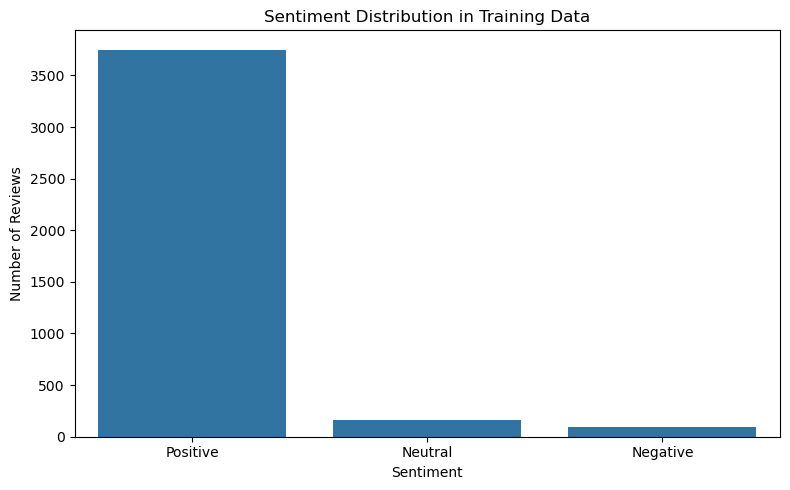

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count sentiment labels in training data
sentiment_counts = train["sentiment"].value_counts()

print("Sentiment counts:")
print(sentiment_counts)

print("\nSentiment percentages:")
print((train["sentiment"].value_counts(normalize=True) * 100).round(2))

# Plot sentiment distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train,
    x="sentiment",
    order=["Positive", "Neutral", "Negative"]
)

plt.title("Sentiment Distribution in Training Data")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

**Getting the exact class counts and percentages**

In [5]:
print("Sentiment counts:")
print(train["sentiment"].value_counts())

print("\nSentiment percentages:")
print(
    (train["sentiment"].value_counts(normalize=True) * 100)
    .round(2)
)

Sentiment counts:
sentiment
Positive    3749
Neutral      158
Negative      93
Name: count, dtype: int64

Sentiment percentages:
sentiment
Positive    93.72
Neutral      3.95
Negative     2.33
Name: proportion, dtype: float64


**This is a highly imbalanced dataset**

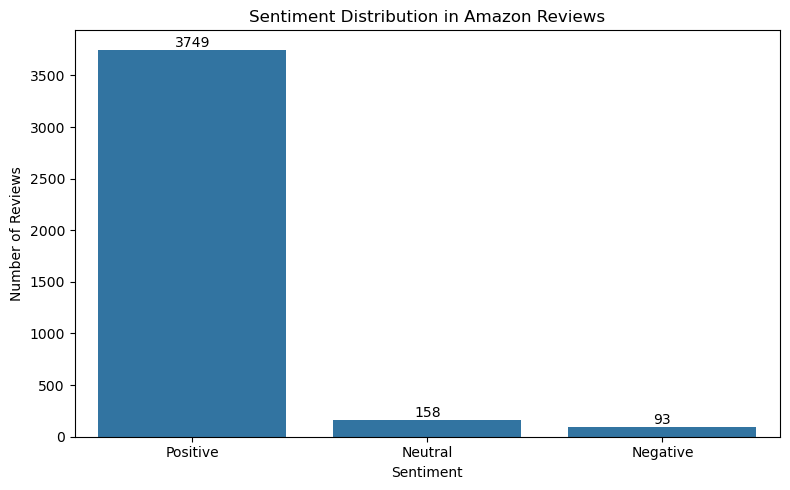

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sentiment_order = ["Positive", "Neutral", "Negative"]

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=train,
    x="sentiment",
    order=sentiment_order
)

plt.title("Sentiment Distribution in Amazon Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

# Display the count above each bar
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{int(height)}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


**We'll check for missing values, duplicate rows, and empty review text.**

In [7]:
print("Missing values in each column:")
print(train.isnull().sum())

print("\nNumber of duplicate rows:")
print(train.duplicated().sum())

print("\nMissing review texts:")
print(train["reviews.text"].isnull().sum())

print("\nEmpty or whitespace-only review texts:")
print(
    train["reviews.text"]
    .fillna("")
    .str.strip()
    .eq("")
    .sum()
)


Missing values in each column:
Name of the product     0
Product Brand           0
categories              0
primaryCategories       0
reviews.date            0
reviews.text            0
reviews.title          10
sentiment               0
dtype: int64

Number of duplicate rows:
58

Missing review texts:
0

Empty or whitespace-only review texts:
0


In [8]:
# Work on a copy so the original data remains unchanged
train_clean = train.copy()

# Replace missing review titles with empty strings
train_clean["reviews.title"] = (
    train_clean["reviews.title"].fillna("")
)

print("Missing titles after handling:")
print(train_clean["reviews.title"].isnull().sum())

print("\nExact duplicate rows:")
print(train_clean.duplicated().sum())

print("\nSample duplicate records:")
display(
    train_clean[
        train_clean.duplicated(keep=False)
    ].head(10)
)


Missing titles after handling:
0

Exact duplicate rows:
58

Sample duplicate records:


,Name of the product,Product Brand,categories,primaryCategories,reviews.date,reviews.text,reviews.title,sentiment
4,"Brand New Amazon Kindle Fire 16gb 7"" Ips Displ...",Amazon,"Computers/Tablets & Networking,Tablets & eBook...",Electronics,2017-01-23T00:00:00.000Z,This is the 3rd one I've purchased. I've bough...,Very durable!,Positive
22,"Brand New Amazon Kindle Fire 16gb 7"" Ips Displ...",Amazon,"Computers/Tablets & Networking,Tablets & eBook...",Electronics,2016-09-13T00:00:00.000Z,For those that have Prime this is almost a mus...,Great tablet for Amazon,Positive
71,"Brand New Amazon Kindle Fire 16gb 7"" Ips Displ...",Amazon,"Computers/Tablets & Networking,Tablets & eBook...",Electronics,2016-07-11T00:00:00.000Z,I use this all the time for playing games and ...,great,Positive
124,"Brand New Amazon Kindle Fire 16gb 7"" Ips Displ...",Amazon,"Computers/Tablets & Networking,Tablets & eBook...",Electronics,2016-08-01T00:00:00.000Z,"bought this kindle for my grandson, he loves i...",great product,Positive
198,"Kindle E-reader - White, 6 Glare-Free Touchscr...",Amazon,"Office,eBook Readers,Electronics Features,Walm...","Office Supplies,Electronics",2017-09-01T00:00:00.000Z,"This is really good if you read a lot, doesn't...",Great buy if you read a lot,Positive
202,"Fire HD 10 Tablet, 10.1 HD Display, Wi-Fi, 16 ...",Amazon,"eBook Readers,Fire Tablets,Electronics Feature...","Office Supplies,Electronics",2017-06-19T00:00:00.000Z,Just writing this review to get my points...Th...,Was a gift to replace a broken kindle,Positive
223,"Brand New Amazon Kindle Fire 16gb 7"" Ips Displ...",Amazon,"Computers/Tablets & Networking,Tablets & eBook...",Electronics,2017-02-18T00:00:00.000Z,I bought this for my daughter who uses it in h...,Great purchase!,Positive
235,"Fire HD 10 Tablet, 10.1 HD Display, Wi-Fi, 16 ...",Amazon,"eBook Readers,Fire Tablets,Electronics Feature...","Office Supplies,Electronics",2017-02-27T00:00:00.000Z,The store representative took his time with me...,I love the large Kindle,Positive
326,"Brand New Amazon Kindle Fire 16gb 7"" Ips Displ...",Amazon,"Computers/Tablets & Networking,Tablets & eBook...",Electronics,2016-07-20T00:00:00.000Z,if you use it for certain things it's great. C...,great for the things I have put on it and use it,Positive
403,"Fire HD 10 Tablet, 10.1 HD Display, Wi-Fi, 16 ...",Amazon,"eBook Readers,Fire Tablets,Electronics Feature...","Office Supplies,Electronics",2017-01-18T00:00:00.000Z,I got the amazon Fire HD 10 for reading and ot...,Fun and Easy to Use,Positive


**Inspect the actual duplicate pairs**

In [9]:

# Show rows that are exact duplicates of another row
duplicate_rows = train_clean[
    train_clean.duplicated(keep=False)
].sort_values(by=list(train_clean.columns))

print("Total rows belonging to duplicate groups:", len(duplicate_rows))

display(duplicate_rows.head(12))


Total rows belonging to duplicate groups: 116


,Name of the product,Product Brand,categories,primaryCategories,reviews.date,reviews.text,reviews.title,sentiment
2635,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",Amazon,"Fire Tablets,Tablets,All Tablets,Amazon Tablets",Electronics,2017-03-04T00:00:00.000Z,The Fire HD8 strikes an excellent balance betw...,Excellent budget tablet,Positive
2754,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",Amazon,"Fire Tablets,Tablets,All Tablets,Amazon Tablets",Electronics,2017-03-04T00:00:00.000Z,The Fire HD8 strikes an excellent balance betw...,Excellent budget tablet,Positive
945,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",Amazon,"Fire Tablets,Tablets,All Tablets,Amazon Tablets",Electronics,2017-04-03T00:00:00.000Z,This tablet is great for my son. Would be nice...,Solid tablet!,Positive
2346,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",Amazon,"Fire Tablets,Tablets,All Tablets,Amazon Tablets",Electronics,2017-04-03T00:00:00.000Z,This tablet is great for my son. Would be nice...,Solid tablet!,Positive
2392,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",Amazon,"Fire Tablets,Tablets,All Tablets,Amazon Tablet...",Electronics,2017-01-17T00:00:00.000Z,Very happy with product. It's a miniature lap ...,Very happy,Positive
2487,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",Amazon,"Fire Tablets,Tablets,All Tablets,Amazon Tablet...",Electronics,2017-01-17T00:00:00.000Z,Very happy with product. It's a miniature lap ...,Very happy,Positive
584,"Brand New Amazon Kindle Fire 16gb 7"" Ips Displ...",Amazon,"Computers/Tablets & Networking,Tablets & eBook...",Electronics,2016-05-27T00:00:00.000Z,"Good tablet for my daughter! She loves it ,but...",Great!,Positive
1131,"Brand New Amazon Kindle Fire 16gb 7"" Ips Displ...",Amazon,"Computers/Tablets & Networking,Tablets & eBook...",Electronics,2016-05-27T00:00:00.000Z,"Good tablet for my daughter! She loves it ,but...",Great!,Positive
527,"Brand New Amazon Kindle Fire 16gb 7"" Ips Displ...",Amazon,"Computers/Tablets & Networking,Tablets & eBook...",Electronics,2016-06-03T00:00:00.000Z,I bought a kindle fire 2 years ago and enjoyed...,Keeps getting better,Positive
3867,"Brand New Amazon Kindle Fire 16gb 7"" Ips Displ...",Amazon,"Computers/Tablets & Networking,Tablets & eBook...",Electronics,2016-06-03T00:00:00.000Z,I bought a kindle fire 2 years ago and enjoyed...,Keeps getting better,Positive


**Removing exact duplicates while keeping the first occurrence**

In [10]:
# Remove exact duplicate rows, keeping the first occurrence
rows_before = len(train_clean)

train_clean = train_clean.drop_duplicates().copy()

rows_after = len(train_clean)

print("Rows before removing duplicates:", rows_before)
print("Rows after removing duplicates:", rows_after)
print("Rows removed:", rows_before - rows_after)
print("Remaining exact duplicates:", train_clean.duplicated().sum())


Rows before removing duplicates: 4000
Rows after removing duplicates: 3942
Rows removed: 58
Remaining exact duplicates: 0


**combining 'reviews.title' and 'reviews.txt'into a single feature called review_text**

In [11]:
# Make sure missing review text is handled
train_clean["reviews.text"] = (
    train_clean["reviews.text"].fillna("")
)

train_clean["reviews.title"] = (
    train_clean["reviews.title"].fillna("")
)

# Combine review title and review body
train_clean["review_text"] = (
    train_clean["reviews.title"].astype(str)
    + " "
    + train_clean["reviews.text"].astype(str)
).str.strip()

# Inspect the result
print(train_clean[[
    "reviews.title",
    "reviews.text",
    "review_text",
    "sentiment"
]].head(5))


              reviews.title  \
0           Powerful tablet   
1  Amazon Echo Plus AWESOME   
2                   Average   
3               Greattttttt   
4             Very durable!   

                                        reviews.text  \
0  Purchased on Black FridayPros - Great Price (e...   
1  I purchased two Amazon in Echo Plus and two do...   
2  Just an average Alexa option. Does show a few ...   
3  very good product. Exactly what I wanted, and ...   
4  This is the 3rd one I've purchased. I've bough...   

                                         review_text sentiment  
0  Powerful tablet Purchased on Black FridayPros ...  Positive  
1  Amazon Echo Plus AWESOME I purchased two Amazo...  Positive  
2  Average Just an average Alexa option. Does sho...   Neutral  
3  Greattttttt very good product. Exactly what I ...  Positive  
4  Very durable! This is the 3rd one I've purchas...  Positive  


**Check the combined text**

In [12]:

print("Dataset shape:", train_clean.shape)

print("\nMissing combined reviews:")
print(train_clean["review_text"].isnull().sum())

print("\nEmpty combined reviews:")
print(train_clean["review_text"].str.strip().eq("").sum())

print("\nExample combined review:")
print(train_clean["review_text"].iloc[0])


Dataset shape: (3942, 9)

Missing combined reviews:
0

Empty combined reviews:
0

Example combined review:
Powerful tablet Purchased on Black FridayPros - Great Price (even off sale)Very powerful and fast with quad core processors Amazing soundWell builtCons -Amazon ads, Amazon need this to subsidize the tablet and will remove the adds if you pay them $15.Inability to access other apps except the ones from Amazon. There is a way which I was able to accomplish to add the Google Play storeNet this is a great tablet for the money


In [13]:
from sklearn.model_selection import train_test_split

# Input feature and target
X = train_clean["review_text"]
y = train_clean["sentiment"]

# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nValidation sentiment distribution:")
print(y_val.value_counts())


Training samples: 3153
Validation samples: 789

Training sentiment distribution:
sentiment
Positive    2955
Neutral      126
Negative      72
Name: count, dtype: int64

Validation sentiment distribution:
sentiment
Positive    739
Neutral      32
Negative     18
Name: count, dtype: int64


**Convert text into numbers using TF-IDF**

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    max_features=20000
)

# Learn vocabulary and IDF weights from training text only
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform validation text using the same vocabulary
X_val_tfidf = tfidf.transform(X_val)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Number of vocabulary features:", len(tfidf.vocabulary_))


Training TF-IDF shape: (3153, 20000)
Validation TF-IDF shape: (789, 20000)
Number of vocabulary features: 20000


**Train our first model - We'll use Multinomial Naive Bayes, a common baseline for text classification**

In [15]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

# Train the baseline model
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

# Predict sentiments for unseen validation reviews
y_pred = nb_model.predict(X_val_tfidf)

# Evaluate the model
print("Validation accuracy:", round(accuracy_score(y_val, y_pred), 4))

print("\nClassification report:")
print(
    classification_report(
        y_val,
        y_pred,
        labels=["Positive", "Neutral", "Negative"],
        zero_division=0
    )
)

# Display the confusion matrix with named classes
labels = ["Positive", "Neutral", "Negative"]

cm = confusion_matrix(y_val, y_pred, labels=labels)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual {label}" for label in labels],
    columns=[f"Predicted {label}" for label in labels]
)

print("\nConfusion matrix:")
display(cm_df)


Validation accuracy: 0.9366

Classification report:
              precision    recall  f1-score   support

    Positive       0.94      1.00      0.97       739
     Neutral       0.00      0.00      0.00        32
    Negative       0.00      0.00      0.00        18

    accuracy                           0.94       789
   macro avg       0.31      0.33      0.32       789
weighted avg       0.88      0.94      0.91       789


Confusion matrix:


,Predicted Positive,Predicted Neutral,Predicted Negative
Actual Positive,739,0,0
Actual Neutral,32,0,0
Actual Negative,18,0,0


**Class Imbalance is preventing the model from recognizing neutral and negative reviews.**

**Running SMOTE**

In [16]:
from imblearn.over_sampling import SMOTE

# Use a small number of neighbors because the minority
# class contains only 72 training examples
smote = SMOTE(
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_tfidf,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())


Before SMOTE:
sentiment
Positive    2955
Neutral      126
Negative      72
Name: count, dtype: int64

After SMOTE:
sentiment
Positive    2955
Neutral     2955
Negative    2955
Name: count, dtype: int64


In [17]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, accuracy_score

nb_smote = MultinomialNB()
nb_smote.fit(X_train_smote, y_train_smote)

y_pred_smote = nb_smote.predict(X_val_tfidf)

print(
    "SMOTE model accuracy:",
    round(accuracy_score(y_val, y_pred_smote), 4)
)

print("\nClassification report:")
print(
    classification_report(
        y_val,
        y_pred_smote,
        labels=["Positive", "Neutral", "Negative"],
        zero_division=0
    )
)


SMOTE model accuracy: 0.9113

Classification report:
              precision    recall  f1-score   support

    Positive       0.97      0.94      0.95       739
     Neutral       0.29      0.50      0.36        32
    Negative       0.50      0.67      0.57        18

    accuracy                           0.91       789
   macro avg       0.59      0.70      0.63       789
weighted avg       0.94      0.91      0.92       789



In [18]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Baseline Naive Bayes", "SMOTE + Naive Bayes"],
    "Accuracy": [0.9366, 0.9113],
    "Macro F1-score": [0.32, 0.63],
    "Positive Recall": [1.00, 0.94],
    "Neutral Recall": [0.00, 0.50],
    "Negative Recall": [0.00, 0.67]
})

display(comparison.round(3))


,Model,Accuracy,Macro F1-score,Positive Recall,Neutral Recall,Negative Recall
0,Baseline Naive Bayes,0.937,0.32,1.00,0.0,0.00
1,SMOTE + Naive Bayes,0.911,0.63,0.94,0.5,0.67


**We'll perform just one more model experiment, using a class-weighted Linear SVM**

In [19]:
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Train the class-weighted SVM
svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42
)

svm_model.fit(X_train_tfidf, y_train)

# Evaluate on the same validation set
y_pred_svm = svm_model.predict(X_val_tfidf)

print("SVM accuracy:", round(accuracy_score(y_val, y_pred_svm), 4))

print(
    "SVM macro F1:",
    round(f1_score(y_val, y_pred_svm, average="macro"), 4)
)

print("\nClassification report:")
print(classification_report(
    y_val,
    y_pred_svm,
    labels=["Positive", "Neutral", "Negative"],
    zero_division=0
))

print("\nConfusion matrix:")
print(confusion_matrix(
    y_val,
    y_pred_svm,
    labels=["Positive", "Neutral", "Negative"]
))


SVM accuracy: 0.9506
SVM macro F1: 0.5937

Classification report:
              precision    recall  f1-score   support

    Positive       0.95      1.00      0.97       739
     Neutral       0.89      0.25      0.39        32
    Negative       0.83      0.28      0.42        18

    accuracy                           0.95       789
   macro avg       0.89      0.51      0.59       789
weighted avg       0.95      0.95      0.94       789


Confusion matrix:
[[737   1   1]
 [ 24   8   0]
 [ 13   0   5]]


**The class-weighted SVM has the highest accuracy, but SMOTE + Naive Bayes has the highest macro F1-score. Since your dataset is heavily imbalanced, we shouldn't select the model based on accuracy alone**


**Final model comparison
Metric	Baseline Naive Bayes	SMOTE + Naive Bayes	Class-weighted SVM
Accuracy	93.66%	91.13%	95.06%
Macro F1-score	0.32	0.63	0.59
Neutral recall	0%	50%	25%
Negative recall	0%	67%	28%
Which model should we choose?**

**SMOTE + Naive Bayes as the provisional final model if balanced performance across all three sentiment classes is our priority. It has the highest macro F1-score and substantially better recall for neutral and negative reviews.**

**Saving the final model and vectorizer**

In [20]:
import joblib

# Save the vectorizer fitted on the original training text
joblib.dump(tfidf, "amazon_tfidf_vectorizer.pkl")

# Save the model trained on SMOTE-balanced training features
joblib.dump(nb_smote, "amazon_smote_nb_model.pkl")

print("Vectorizer saved successfully.")
print("SMOTE Naive Bayes model saved successfully.")


Vectorizer saved successfully.
SMOTE Naive Bayes model saved successfully.


In [21]:

import pandas as pd

# Load the unlabeled test dataset
test = pd.read_csv("test_data.csv")

# Handle missing text values
test["reviews.title"] = test["reviews.title"].fillna("")
test["reviews.text"] = test["reviews.text"].fillna("")

# Combine title and review body in the same format as training
test["review_text"] = (
    test["reviews.title"].astype(str)
    + " "
    + test["reviews.text"].astype(str)
).str.strip()

# Transform with the already-fitted vectorizer
X_test_tfidf = tfidf.transform(test["review_text"])

# Predict sentiment using the selected model
test["predicted_sentiment"] = nb_smote.predict(X_test_tfidf)

print("Prediction counts:")
print(test["predicted_sentiment"].value_counts())

print("\nFirst five predictions:")
display(
    test[["reviews.title", "reviews.text", "predicted_sentiment"]].head()
)

# Export predictions
test.to_csv("amazon_sentiment_predictions.csv", index=False)

print("\nPredictions saved to amazon_sentiment_predictions.csv")


Prediction counts:
predicted_sentiment
Positive    893
Neutral      76
Negative     31
Name: count, dtype: int64

First five predictions:


,reviews.title,reviews.text,predicted_sentiment
0,very handy device,Amazon kindle fire has a lot of free app and c...,Positive
1,Another winner from Amazon,The Echo Show is a great addition to the Amazo...,Positive
2,simple to use and reliable so far,Great value from Best Buy. Bought at Christmas...,Positive
3,Love it!!!,"I use mine for email, Facebook ,games and to g...",Positive
4,Fantastic!,This is a fantastic item & the person I bought...,Positive



Predictions saved to amazon_sentiment_predictions.csv


In [22]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Load the labeled holdout dataset
hidden = pd.read_csv("test_data_hidden.csv")

# Prepare text in exactly the same way as the training data
hidden["reviews.title"] = hidden["reviews.title"].fillna("")
hidden["reviews.text"] = hidden["reviews.text"].fillna("")

hidden["review_text"] = (
    hidden["reviews.title"].astype(str)
    + " "
    + hidden["reviews.text"].astype(str)
).str.strip()

# Generate predictions using the selected model
X_hidden_tfidf = tfidf.transform(hidden["review_text"])
y_hidden = hidden["sentiment"]
y_hidden_pred = nb_smote.predict(X_hidden_tfidf)

# Final holdout evaluation
print("Holdout accuracy:",
      round(accuracy_score(y_hidden, y_hidden_pred), 4))

print("Holdout macro F1:",
      round(f1_score(y_hidden, y_hidden_pred, average="macro"), 4))

print("\nClassification report:")
print(classification_report(
    y_hidden,
    y_hidden_pred,
    labels=["Positive", "Neutral", "Negative"],
    zero_division=0
))

print("\nConfusion matrix:")
print(confusion_matrix(
    y_hidden,
    y_hidden_pred,
    labels=["Positive", "Neutral", "Negative"]
))


Holdout accuracy: 0.898
Holdout macro F1: 0.5497

Classification report:
              precision    recall  f1-score   support

    Positive       0.98      0.93      0.95       937
     Neutral       0.20      0.38      0.26        39
    Negative       0.39      0.50      0.44        24

    accuracy                           0.90      1000
   macro avg       0.52      0.60      0.55      1000
weighted avg       0.93      0.90      0.91      1000


Confusion matrix:
[[871  53  13]
 [ 18  15   6]
 [  4   8  12]]


In [23]:

import pandas as pd

final_results = pd.DataFrame({
    "Metric": [
        "Holdout accuracy",
        "Holdout macro F1-score",
        "Positive recall",
        "Neutral recall",
        "Negative recall"
    ],
    "Score": [
        0.8980,
        0.5497,
        0.93,
        15 / 39,
        12 / 24
    ]
})

display(final_results.round(4))


,Metric,Score
0,Holdout accuracy,0.8980
1,Holdout macro F1-score,0.5497
2,Positive recall,0.9300
3,Neutral recall,0.3846
4,Negative recall,0.5000


**Interpretation:
- Accuracy (89.80%): The model correctly classified nearly 90% of holdout reviews.
- Macro F1-score (0.5497): Performance across the three sentiment classes is uneven, despite the high accuracy.
- Positive recall (93%): The model identifies most positive reviews correctly.
- Neutral recall (38.46%): It misses many neutral reviews.
- Negative recall (50%): It identifies half of the actual negative reviews.**

## Final Project Deliverables

In [24]:

import os

files_to_check = [
    "train_data.csv",
    "test_data.csv",
    "test_data_hidden.csv",
    "amazon_tfidf_vectorizer.pkl",
    "amazon_smote_nb_model.pkl",
    "amazon_sentiment_predictions.csv"
]

for file in files_to_check:
    if os.path.exists(file):
        print(f"FOUND: {file}")
    else:
        print(f"MISSING: {file}")


FOUND: train_data.csv
FOUND: test_data.csv
FOUND: test_data_hidden.csv
FOUND: amazon_tfidf_vectorizer.pkl
FOUND: amazon_smote_nb_model.pkl
FOUND: amazon_sentiment_predictions.csv


In [25]:
import pandas as pd
import joblib

# Load the saved prediction file
predictions = pd.read_csv("amazon_sentiment_predictions.csv")

# Load the saved model and vectorizer
loaded_model = joblib.load("amazon_smote_nb_model.pkl")
loaded_tfidf = joblib.load("amazon_tfidf_vectorizer.pkl")

# Check the prediction file
print("Prediction file shape:", predictions.shape)
print("\nColumn names:")
print(predictions.columns.tolist())

print("\nPredicted sentiment counts:")
print(predictions["predicted_sentiment"].value_counts())

print("\nMissing values in predicted sentiment:",
      predictions["predicted_sentiment"].isna().sum())

print("\nUnexpected sentiment labels:",
      set(predictions["predicted_sentiment"].dropna().unique())
      - {"Positive", "Neutral", "Negative"})

print("\nSaved model:", type(loaded_model).__name__)
print("Saved vectorizer:", type(loaded_tfidf).__name__)


Prediction file shape: (1000, 9)

Column names:
['Name of the product', 'Product Brand', 'categories', 'primaryCategories', 'reviews.date', 'reviews.text', 'reviews.title', 'review_text', 'predicted_sentiment']

Predicted sentiment counts:
predicted_sentiment
Positive    893
Neutral      76
Negative     31
Name: count, dtype: int64

Missing values in predicted sentiment: 0

Unexpected sentiment labels: set()

Saved model: MultinomialNB
Saved vectorizer: TfidfVectorizer


AUC-ROC Evaluation: SMOTE + Multinomial Naive Bayes
-------------------------------------------------------
Macro-average ROC-AUC:    0.8908
Weighted-average ROC-AUC: 0.9089


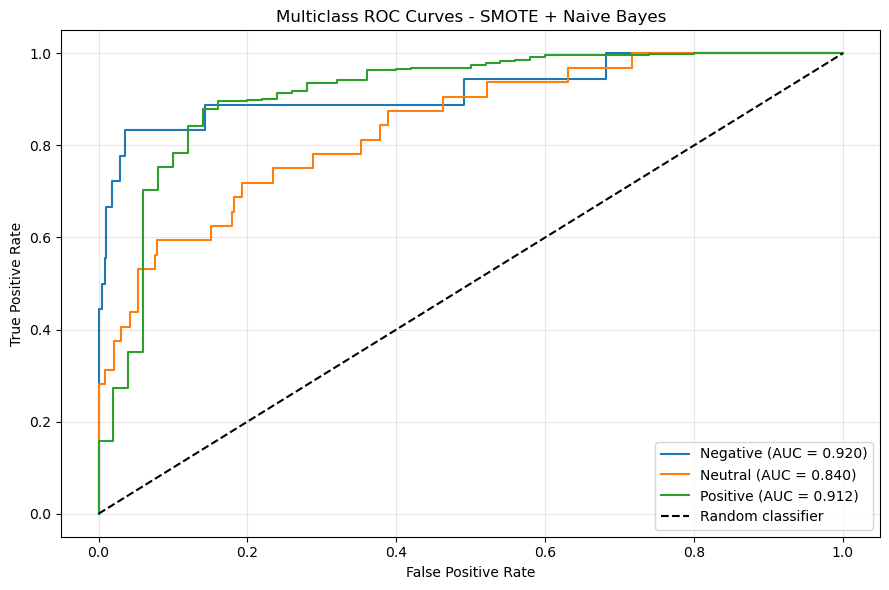

In [26]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score, roc_curve, auc
from sklearn.preprocessing import label_binarize

# Use alphabetical order for the class labels
class_order = ["Negative", "Neutral", "Positive"]

# Actual validation labels
y_val_array = np.asarray(y_val)

# Get predicted probabilities
y_val_proba = nb_smote.predict_proba(X_val_tfidf)

# Arrange probability columns in the correct order
model_classes = list(nb_smote.classes_)

proba_df = pd.DataFrame(
    y_val_proba,
    columns=model_classes
)

y_val_proba_ordered = proba_df[class_order].to_numpy()

# Calculate multiclass ROC-AUC
macro_auc = roc_auc_score(
    y_val_array,
    y_val_proba_ordered,
    labels=class_order,
    multi_class="ovr",
    average="macro"
)

weighted_auc = roc_auc_score(
    y_val_array,
    y_val_proba_ordered,
    labels=class_order,
    multi_class="ovr",
    average="weighted"
)

print("AUC-ROC Evaluation: SMOTE + Multinomial Naive Bayes")
print("-" * 55)
print(f"Macro-average ROC-AUC:    {macro_auc:.4f}")
print(f"Weighted-average ROC-AUC: {weighted_auc:.4f}")

# Convert actual labels to binary format for each class
y_val_binary = label_binarize(
    y_val_array,
    classes=class_order
)

# Plot ROC curves
plt.figure(figsize=(9, 6))

for i, sentiment in enumerate(class_order):
    fpr, tpr, thresholds = roc_curve(
        y_val_binary[:, i],
        y_val_proba_ordered[:, i]
    )

    class_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{sentiment} (AUC = {class_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves - SMOTE + Naive Bayes")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### AUC-ROC Evaluation

The SMOTE-based Multinomial Naive Bayes model was evaluated using multiclass ROC-AUC with a One-vs-Rest (OvR) approach.

- **Macro-average ROC-AUC:** 0.8908
- **Weighted-average ROC-AUC:** 0.9089

The results indicate that the model has good overall ability to distinguish between sentiment classes. The weighted-average score is higher than the macro-average score, suggesting that performance across the more frequent classes contributes positively to the overall result. However, ROC-AUC should be interpreted alongside precision, recall, and F1-score, particularly because Neutral and Negative reviews are underrepresented.

In [27]:
%pip install vaderSentiment

Note: you may need to restart the kernel to use updated packages.


In [28]:

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import pandas as pd
import matplotlib.pyplot as plt

# Initialize VADER
analyzer = SentimentIntensityAnalyzer()

# Calculate sentiment scores for each review
vader_scores = train_clean["review_text"].apply(
    lambda text: analyzer.polarity_scores(str(text))
)

# Add the scores as new columns
train_clean["vader_positive"] = vader_scores.apply(
    lambda score: score["pos"]
)
train_clean["vader_neutral"] = vader_scores.apply(
    lambda score: score["neu"]
)
train_clean["vader_negative"] = vader_scores.apply(
    lambda score: score["neg"]
)
train_clean["vader_compound"] = vader_scores.apply(
    lambda score: score["compound"]
)

# Display example reviews and their scores
display(
    train_clean[
        ["review_text", "sentiment", "vader_compound",
         "vader_positive", "vader_neutral", "vader_negative"]
    ].head(10)
)

# Summarize compound scores for each actual sentiment class
print("Average VADER compound score by actual sentiment:")
display(
    train_clean.groupby("sentiment")["vader_compound"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(3)
)


,review_text,sentiment,vader_compound,vader_positive,vader_neutral,vader_negative
0,Powerful tablet Purchased on Black FridayPros ...,Positive,0.9764,0.302,0.683,0.015
1,Amazon Echo Plus AWESOME I purchased two Amazo...,Positive,0.9825,0.227,0.756,0.017
2,Average Just an average Alexa option. Does sho...,Neutral,-0.3291,0.000,0.865,0.135
3,Greattttttt very good product. Exactly what I ...,Positive,0.7496,0.367,0.633,0.000
4,Very durable! This is the 3rd one I've purchas...,Positive,0.2481,0.079,0.867,0.054
5,You will love it This is a great product. Ligh...,Positive,0.9001,0.393,0.607,0.000
6,OK For Entry Level Tablet My 7-year old daught...,Neutral,0.9739,0.231,0.712,0.057
7,Great for kids or smaller needs Purchased this...,Positive,0.8934,0.281,0.719,0.000
8,Great tablet Bought this for my mom and it was...,Positive,0.9246,0.266,0.734,0.000
9,"was cheap, can not run chrome stuff, returned ...",Negative,0.0000,0.000,1.000,0.000


Average VADER compound score by actual sentiment:


,count,mean,median,min,max
sentiment,,,,,
Negative,90,-0.217,-0.339,-0.926,0.955
Neutral,158,0.438,0.661,-0.761,0.976
Positive,3694,0.808,0.883,-0.821,0.999


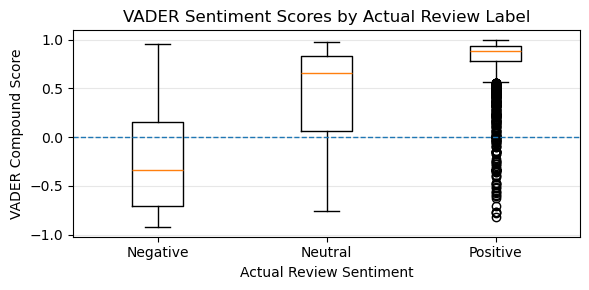

In [29]:

# Compare compound sentiment scores across the actual labels
sentiment_order = ["Negative", "Neutral", "Positive"]

score_groups = [
    train_clean.loc[
        train_clean["sentiment"] == label,
        "vader_compound"
    ].dropna()
    for label in sentiment_order
]

plt.figure(figsize=(6, 3))
plt.boxplot(score_groups, tick_labels=sentiment_order)
plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Actual Review Sentiment")
plt.ylabel("VADER Compound Score")
plt.title("VADER Sentiment Scores by Actual Review Label")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [30]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import pandas as pd

# Convert VADER compound scores into sentiment predictions
def vader_label(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

train_clean["vader_predicted_sentiment"] = (
    train_clean["vader_compound"].apply(vader_label)
)

# Actual and predicted sentiment labels
y_actual = train_clean["sentiment"]
y_vader = train_clean["vader_predicted_sentiment"]

# Classification report
print("VADER Classification Report")
print("-" * 50)

print(classification_report(
    y_actual,
    y_vader,
    labels=["Positive", "Neutral", "Negative"],
    zero_division=0
))

print("VADER Accuracy:", round(accuracy_score(y_actual, y_vader), 4))
print("VADER Macro F1:", round(
    f1_score(
        y_actual,
        y_vader,
        labels=["Positive", "Neutral", "Negative"],
        average="macro",
        zero_division=0
    ), 4
))


VADER Classification Report
--------------------------------------------------
              precision    recall  f1-score   support

    Positive       0.96      0.97      0.97      3694
     Neutral       0.16      0.06      0.08       158
    Negative       0.40      0.63      0.49        90

    accuracy                           0.93      3942
   macro avg       0.51      0.55      0.51      3942
weighted avg       0.92      0.93      0.92      3942

VADER Accuracy: 0.929
VADER Macro F1: 0.5134


## Display the confusion matrix

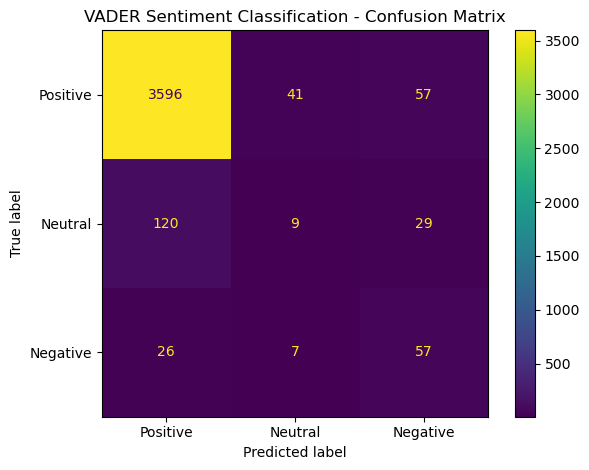

In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

class_order = ["Positive", "Neutral", "Negative"]

cm = confusion_matrix(
    y_actual,
    y_vader,
    labels=class_order
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_order
)

disp.plot(values_format="d")
plt.title("VADER Sentiment Classification - Confusion Matrix")
plt.tight_layout()
plt.show()


**VADER Sentiment Classification Evaluation**

VADER was evaluated by comparing its compound-score-based sentiment predictions with the actual sentiment labels.

The confusion matrix shows that VADER correctly classified 3,596 Positive reviews, 9 Neutral reviews, and 57 Negative reviews. It performed best on Positive reviews but struggled to identify Neutral reviews, frequently classifying them as Positive. Some Negative reviews were also incorrectly predicted as Positive.

These results suggest that lexicon-based sentiment analysis can identify clearly positive language but may struggle with context-dependent or less explicit sentiment. The severe class imbalance in the dataset also makes it important to evaluate macro F1-score, precision, and recall alongside accuracy.

VADER provides a useful baseline for comparison with machine-learning models such as TF-IDF with SMOTE and Multinomial Naive Bayes.

In [32]:

# Evaluate VADER on the same validation reviews used by the ML models

from sklearn.metrics import accuracy_score, f1_score, classification_report

# Use the validation reviews and their true labels
X_val_text = X_val if isinstance(X_val, pd.Series) else pd.Series(X_val)

vader_val_scores = X_val_text.apply(
    lambda text: analyzer.polarity_scores(str(text))["compound"]
)

y_vader_val = vader_val_scores.apply(vader_label)

print("VADER Validation Results")
print("-" * 40)

print("Accuracy:", round(accuracy_score(y_val, y_vader_val), 4))
print("Macro F1:", round(f1_score(
    y_val,
    y_vader_val,
    labels=["Positive", "Neutral", "Negative"],
    average="macro",
    zero_division=0
), 4))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_vader_val,
    labels=["Positive", "Neutral", "Negative"],
    zero_division=0
))


VADER Validation Results
----------------------------------------
Accuracy: 0.9366
Macro F1: 0.5486

Classification Report:
              precision    recall  f1-score   support

    Positive       0.97      0.98      0.97       739
     Neutral       0.30      0.09      0.14        32
    Negative       0.42      0.72      0.53        18

    accuracy                           0.94       789
   macro avg       0.56      0.60      0.55       789
weighted avg       0.93      0.94      0.93       789



### Comparison of VADER and Machine-Learning Models

VADER achieved a validation accuracy of 93.66% and a macro F1-score of 0.5486. It performed strongly on Positive reviews but showed weak performance on Neutral reviews, with a Neutral recall of 0.09. Its Negative recall was 0.72, indicating that it identified many of the Negative reviews.

The SMOTE-based Multinomial Naive Bayes model achieved a validation accuracy of 91.13% and a macro F1-score of 0.6300. The class-weighted SVM achieved an accuracy of 95.06% and a macro F1-score of 0.5937.

Although SVM achieved the highest accuracy, SMOTE-based Multinomial Naive Bayes achieved the highest macro F1-score among the three models. This suggests that the SMOTE-based model offers a better balance across sentiment classes. The results also demonstrate why imbalanced classification should be evaluated using precision, recall, and F1-score alongside accuracy.

,Model,Accuracy,Macro F1
0,VADER,0.9366,0.5486
1,SMOTE + MultinomialNB,0.9113,0.6300
2,Class-weighted SVM,0.9506,0.5937


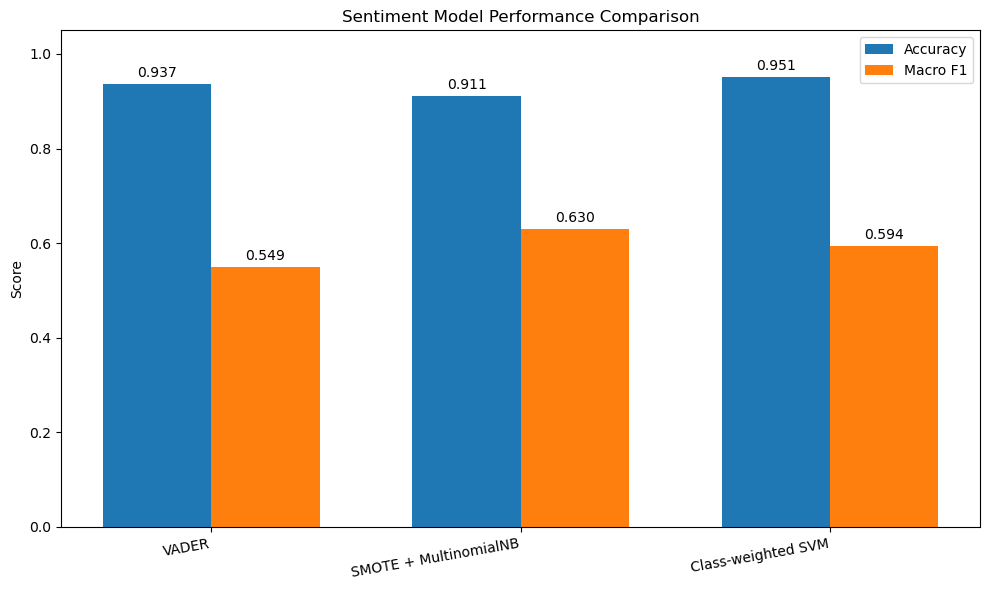

In [33]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Model comparison results from your validation experiments
comparison = pd.DataFrame({
    "Model": [
        "VADER",
        "SMOTE + MultinomialNB",
        "Class-weighted SVM"
    ],
    "Accuracy": [0.9366, 0.9113, 0.9506],
    "Macro F1": [0.5486, 0.6300, 0.5937]
})

display(comparison.round(4))

# Plot comparison
x = np.arange(len(comparison))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width / 2,
    comparison["Accuracy"],
    width,
    label="Accuracy"
)

bars2 = ax.bar(
    x + width / 2,
    comparison["Macro F1"],
    width,
    label="Macro F1"
)

ax.set_ylabel("Score")
ax.set_title("Sentiment Model Performance Comparison")
ax.set_xticks(x)
ax.set_xticklabels(comparison["Model"], rotation=10, ha="right")
ax.set_ylim(0, 1.05)
ax.legend()

ax.bar_label(bars1, fmt="%.3f", padding=3)
ax.bar_label(bars2, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()


In [34]:

# Check that the cleaned review text is available
print("Dataset shape:", train_clean.shape)
print("Review text column available:", "review_text" in train_clean.columns)

train_clean[["review_text", "sentiment"]].head()


Dataset shape: (3942, 14)
Review text column available: True


,review_text,sentiment
0,Powerful tablet Purchased on Black FridayPros ...,Positive
1,Amazon Echo Plus AWESOME I purchased two Amazo...,Positive
2,Average Just an average Alexa option. Does sho...,Neutral
3,Greattttttt very good product. Exactly what I ...,Positive
4,Very durable! This is the 3rd one I've purchas...,Positive


In [35]:

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Use review text for topic modelling
reviews = train_clean["review_text"].fillna("").astype(str)

# Convert reviews into a document-term matrix
count_vectorizer = CountVectorizer(
    stop_words="english",
    max_df=0.95,
    min_df=3,
    max_features=5000
)

document_term_matrix = count_vectorizer.fit_transform(reviews)

print("Document-term matrix shape:", document_term_matrix.shape)

# Discover 5 common topics
lda_model = LatentDirichletAllocation(
    n_components=5,
    random_state=42,
    max_iter=10,
    learning_method="batch"
)

lda_model.fit(document_term_matrix)

# Display the top 10 words for each topic
feature_names = count_vectorizer.get_feature_names_out()

for topic_idx, topic in enumerate(lda_model.components_):
    top_word_indices = topic.argsort()[-10:][::-1]
    top_words = [feature_names[i] for i in top_word_indices]

    print(f"\nTopic {topic_idx + 1}:")
    print(", ".join(top_words))


Document-term matrix shape: (3942, 2044)

Topic 1:
echo, great, amazon, home, sound, alexa, love, product, good, smart

Topic 2:
great, tablet, loves, bought, gift, easy, use, price, old, love

Topic 3:
tablet, kids, great, good, apps, amazon, love, price, bought, play

Topic 4:
love, great, alexa, echo, use, music, fun, easy, just, like

Topic 5:
kindle, reading, read, great, good, books, reader, use, love, like


### Topic Modelling Using Latent Dirichlet Allocation (LDA)

LDA topic modelling was applied to 3,942 cleaned Amazon product reviews. The CountVectorizer transformed the review text into a document-term matrix containing 2,044 word features. An LDA model with five topics was then trained to identify recurring word patterns.

The discovered topics were interpreted as follows:

1. **Smart Home Devices and Sound:** Echo, Alexa, sound, home, and smart.
2. **Tablet Purchases and Value:** tablet, bought, gift, price, and ease of use.
3. **Tablets for Children and Apps:** kids, tablet, apps, and play.
4. **Alexa, Music, and Ease of Use:** Alexa, Echo, music, fun, and easy.
5. **Kindle and Reading Experience:** Kindle, reading, books, and reader.

The results indicate that customer discussions frequently involve smart-home devices, tablets, children's entertainment, voice-assistant features, and e-reading. These insights can help identify common areas of customer interest.

Some topics contain overlapping terms, particularly those relating to Echo devices and tablets. Therefore, the topics should be interpreted as exploratory themes rather than completely distinct categories.

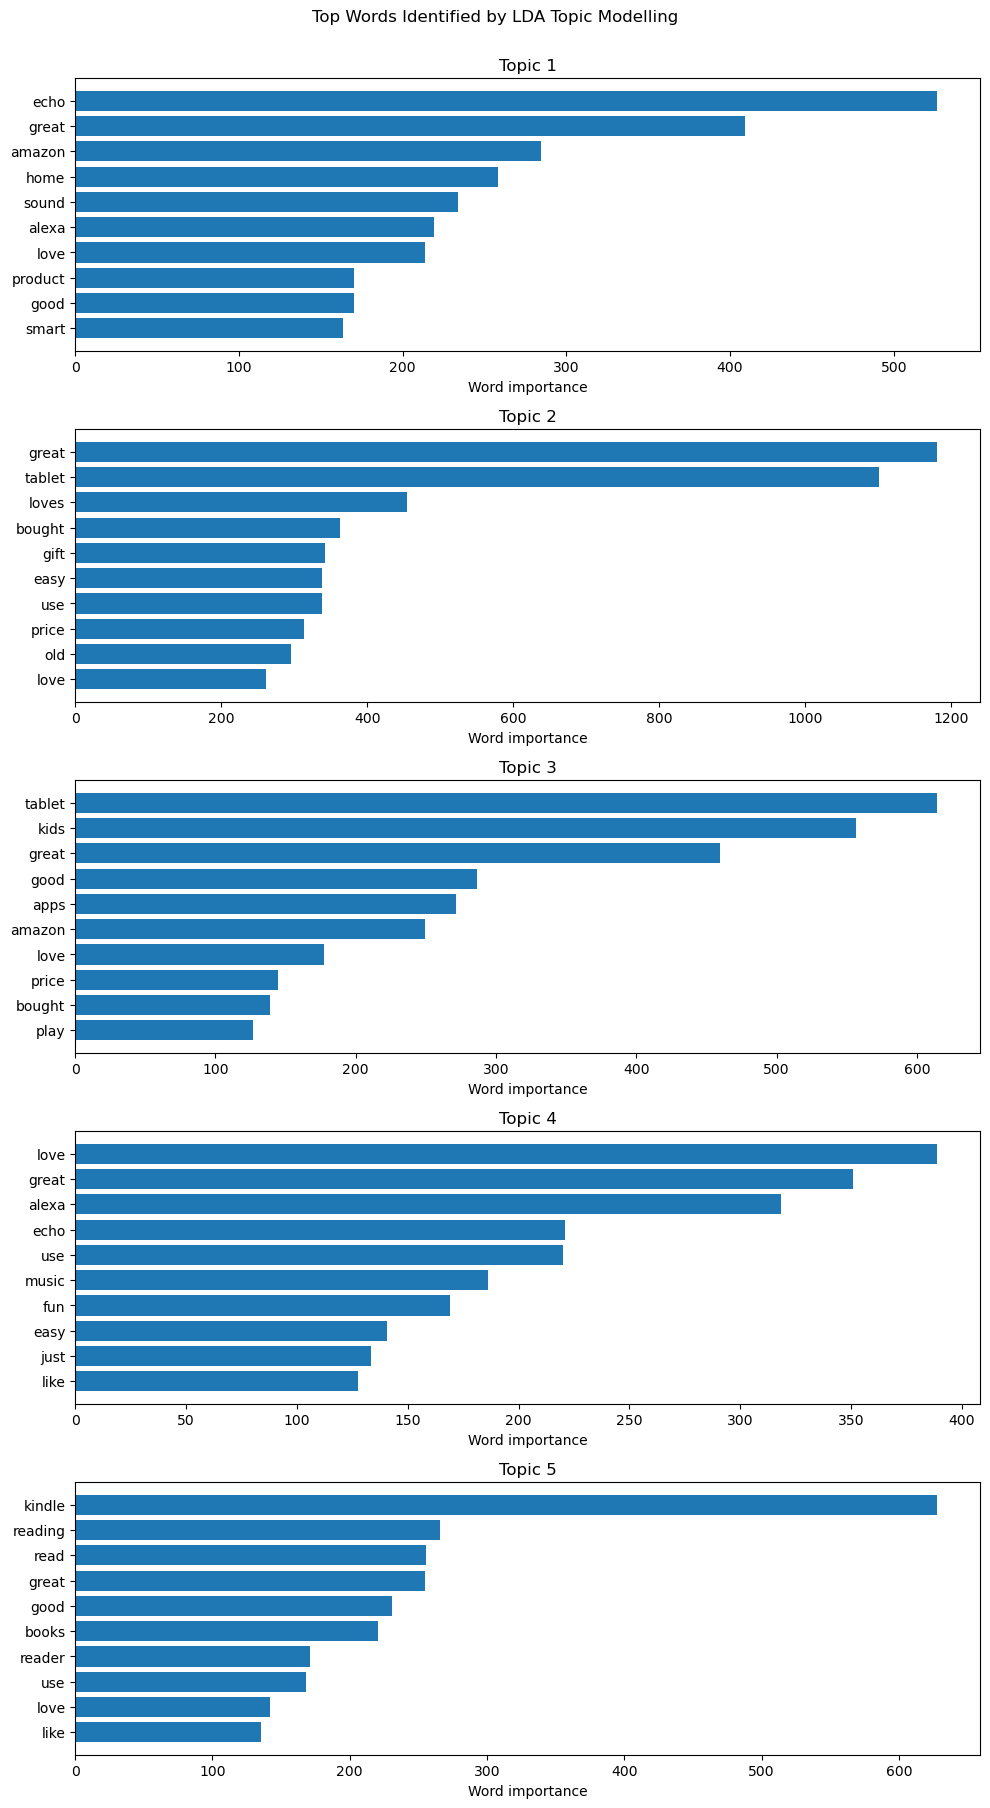

In [36]:
import matplotlib.pyplot as plt

feature_names = count_vectorizer.get_feature_names_out()
n_topics = lda_model.n_components

fig, axes = plt.subplots(n_topics, 1, figsize=(10, 18))

for topic_idx, ax in enumerate(axes):
    topic_weights = lda_model.components_[topic_idx]
    top_indices = topic_weights.argsort()[-10:]

    words = feature_names[top_indices]
    weights = topic_weights[top_indices]

    ax.barh(words, weights)
    ax.set_title(f"Topic {topic_idx + 1}")
    ax.set_xlabel("Word importance")

plt.suptitle("Top Words Identified by LDA Topic Modelling", y=1.002)
plt.tight_layout()
plt.show()


In [37]:
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert reviews into TF-IDF features for NMF
nmf_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_df=0.95,
    min_df=3,
    max_features=5000
)

tfidf_matrix_nmf = nmf_vectorizer.fit_transform(
    train_clean["review_text"].fillna("").astype(str)
)

# Fit the NMF model with 5 topics
nmf_model = NMF(
    n_components=5,
    random_state=42,
    max_iter=400,
    init="nndsvda"
)

nmf_model.fit(tfidf_matrix_nmf)

# Display the top 10 words for each topic
nmf_features = nmf_vectorizer.get_feature_names_out()

print("NMF Topic Modelling Results")
print("-" * 40)

for topic_idx, topic in enumerate(nmf_model.components_):
    top_indices = topic.argsort()[-10:][::-1]
    top_words = [nmf_features[i] for i in top_indices]

    print(f"\nTopic {topic_idx + 1}:")
    print(", ".join(top_words))


NMF Topic Modelling Results
----------------------------------------

Topic 1:
tablet, kids, great, loves, old, year, bought, daughter, price, games

Topic 2:
echo, love, alexa, amazon, music, plus, home, fun, smart, awesome

Topic 3:
product, great, good, price, works, recommend, sound, quality, buy, value

Topic 4:
easy, use, set, fun, setup, super, bought, like, navigate, gift

Topic 5:
kindle, love, books, reading, read, size, new, screen, best, reader


### Comparison of LDA and NMF Topic Modelling

Both Latent Dirichlet Allocation (LDA) and Non-negative Matrix Factorization (NMF) were applied to the cleaned Amazon reviews using five topics.

LDA identified themes relating to smart-home devices, tablet purchases, children's entertainment, Alexa and music, and Kindle reading. NMF identified similar themes while also highlighting product quality, value for money, and ease of setup.

The two methods showed overlap in their discovered topics, indicating recurring customer discussion areas across the reviews. However, the methods produced somewhat different word groupings because they use different mathematical approaches.

This analysis demonstrates how unsupervised topic modelling can help summarize large collections of product reviews and identify themes that may be useful for understanding customer interests and product experiences. The topics are exploratory and should not be interpreted as definitive categories without further validation.

In [38]:

# Check whether the required variables are available

required_variables = [
    "X_train_tfidf",
    "X_val_tfidf",
    "y_train",
    "y_val",
    "nb_smote"
]

for var_name in required_variables:
    print(f"{var_name}: {'Available' if var_name in globals() else 'Not available'}")


X_train_tfidf: Available
X_val_tfidf: Available
y_train: Available
y_val: Available
nb_smote: Available


In [39]:
try:
    import xgboost
    print("XGBoost is installed.")
    print("Version:", xgboost.__version__)
except ImportError:
    print("XGBoost is not installed.")

XGBoost is not installed.


In [40]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 318.9 kB/s eta 0:02:32
   ---------------------------------------- 0.5/48.9 MB 318.9 kB/s eta 0:02:32
   ---------------------------------------- 0.5/48.9 MB 318.9 kB/s eta 0:02:32
    --------------------------------------- 0.8/48.9 MB 362.0 k

In [41]:
import xgboost

print("XGBoost installed successfully!")
print("Version:", xgboost.__version__)

XGBoost installed successfully!
Version: 3.4.1


In [42]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight

# Encode sentiment labels as numbers for XGBoost
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)

# Give more weight to underrepresented sentiment classes
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_encoded
)

# Initialize XGBoost
xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(
    X_train_tfidf,
    y_train_encoded,
    sample_weight=sample_weights
)

print("XGBoost model trained successfully!")
print("Sentiment classes:", label_encoder.classes_)

XGBoost model trained successfully!
Sentiment classes: ['Negative' 'Neutral' 'Positive']


**Evaluate XGBoost**

In [43]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Predict validation sentiments
xgb_val_encoded = xgb_model.predict(X_val_tfidf)
xgb_val_predictions = label_encoder.inverse_transform(
    xgb_val_encoded.astype(int)
)

# Evaluate performance
print("XGBoost Validation Results")
print("Accuracy:", round(accuracy_score(y_val, xgb_val_predictions), 4))
print("Macro F1:", round(
    f1_score(y_val, xgb_val_predictions, average="macro"),
    4
))

print("\nClassification Report:")
print(classification_report(
    y_val,
    xgb_val_predictions,
    labels=["Positive", "Neutral", "Negative"],
    zero_division=0
))

XGBoost Validation Results
Accuracy: 0.9176
Macro F1: 0.5852

Classification Report:
              precision    recall  f1-score   support

    Positive       0.97      0.95      0.96       739
     Neutral       0.33      0.38      0.35        32
    Negative       0.37      0.56      0.44        18

    accuracy                           0.92       789
   macro avg       0.56      0.63      0.59       789
weighted avg       0.93      0.92      0.92       789



**Combining Naive Bayes and XGBoost**

In [44]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Get class probabilities from both models
nb_val_proba = nb_smote.predict_proba(X_val_tfidf)
xgb_val_proba = xgb_model.predict_proba(X_val_tfidf)

# Align XGBoost probabilities to the Naive Bayes class order
nb_classes = list(nb_smote.classes_)
xgb_class_order = list(label_encoder.classes_)

xgb_indices = [
    xgb_class_order.index(label)
    for label in nb_classes
]

xgb_val_proba_aligned = xgb_val_proba[:, xgb_indices]

# Average the two models' probabilities
ensemble_val_proba = (
    0.5 * nb_val_proba +
    0.5 * xgb_val_proba_aligned
)

# Convert probabilities into predicted sentiments
ensemble_indices = np.argmax(ensemble_val_proba, axis=1)
ensemble_predictions = np.array(nb_classes)[ensemble_indices]

# Evaluate the ensemble
print("Ensemble Validation Results")
print("Accuracy:", round(
    accuracy_score(y_val, ensemble_predictions), 4
))
print("Macro F1:", round(
    f1_score(y_val, ensemble_predictions, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(
    y_val,
    ensemble_predictions,
    labels=["Positive", "Neutral", "Negative"],
    zero_division=0
))

Ensemble Validation Results
Accuracy: 0.9417
Macro F1: 0.6727

Classification Report:
              precision    recall  f1-score   support

    Positive       0.97      0.97      0.97       739
     Neutral       0.38      0.34      0.36        32
    Negative       0.71      0.67      0.69        18

    accuracy                           0.94       789
   macro avg       0.68      0.66      0.67       789
weighted avg       0.94      0.94      0.94       789



### Ensemble Modelling: SMOTE + Naive Bayes and XGBoost

An ensemble model was developed by combining the class probabilities from a SMOTE-trained Multinomial Naive Bayes classifier and an XGBoost classifier. The probabilities were averaged equally to generate the final sentiment predictions.

On the validation dataset, the ensemble achieved an accuracy of **94.17%** and a macro F1 score of **0.6727**. The Positive, Neutral, and Negative classes achieved F1 scores of 0.97, 0.36, and 0.69, respectively.

Compared with SMOTE + Naive Bayes alone, the ensemble improved accuracy from 91.13% to 94.17% and macro F1 from 0.6300 to 0.6727. The Negative-class F1 score also increased from 0.57 to 0.69.

These results suggest that combining two different classifiers improved overall performance and the detection of minority-class sentiment. However, Neutral sentiment remains challenging because of the small number of Neutral examples. The ensemble should be considered a promising candidate rather than a definitive final model until it has been compared fairly with the other models and evaluated on appropriate held-out data.


In [45]:
# Check whether VADER sentiment scores are available

vader_columns = [
    "vader_positive",
    "vader_neutral",
    "vader_negative",
    "vader_compound"
]

print("VADER columns available:")

for col in vader_columns:
    print(f"{col}: {col in train_clean.columns}")

VADER columns available:
vader_positive: True
vader_neutral: True
vader_negative: True
vader_compound: True


In [46]:
from scipy.sparse import hstack, csr_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Get VADER scores for the training and validation reviews
vader_features = [
    "vader_positive",
    "vader_neutral",
    "vader_negative",
    "vader_compound"
]

# Match the rows in the original train/validation split
train_indices = X_train.index
val_indices = X_val.index

X_train_vader = csr_matrix(
    train_clean.loc[train_indices, vader_features].values
)

X_val_vader = csr_matrix(
    train_clean.loc[val_indices, vader_features].values
)

# Combine text TF-IDF features with VADER scores
X_train_combined = hstack([X_train_tfidf, X_train_vader]).tocsr()
X_val_combined = hstack([X_val_tfidf, X_val_vader]).tocsr()

print("Combined training shape:", X_train_combined.shape)
print("Combined validation shape:", X_val_combined.shape)


Combined training shape: (3153, 20004)
Combined validation shape: (789, 20004)


**Training the combined-feature model**

In [47]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Train Logistic Regression using TF-IDF + VADER features
lr_vader_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

lr_vader_model.fit(X_train_combined, y_train)

# Predict validation sentiments
vader_ml_predictions = lr_vader_model.predict(X_val_combined)

# Evaluate the model
print("Logistic Regression + VADER Results")
print("Accuracy:", round(
    accuracy_score(y_val, vader_ml_predictions), 4
))
print("Macro F1:", round(
    f1_score(y_val, vader_ml_predictions, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(
    y_val,
    vader_ml_predictions,
    labels=["Positive", "Neutral", "Negative"],
    zero_division=0
))


Logistic Regression + VADER Results
Accuracy: 0.9252
Macro F1: 0.6036

Classification Report:
              precision    recall  f1-score   support

    Positive       0.98      0.95      0.97       739
     Neutral       0.34      0.34      0.34        32
    Negative       0.37      0.78      0.50        18

    accuracy                           0.93       789
   macro avg       0.56      0.69      0.60       789
weighted avg       0.94      0.93      0.93       789



### Integrating VADER Sentiment Scores with Machine Learning

VADER sentiment scores were integrated with TF-IDF text features to train a class-weighted Logistic Regression classifier. Four additional features were included: positive sentiment score, neutral sentiment score, negative sentiment score, and compound sentiment score.

The model achieved a validation accuracy of **92.52%** and a macro F1 score of **0.6036**. The F1 scores for Positive, Neutral, and Negative sentiment were 0.97, 0.34, and 0.50, respectively.

The model achieved a Negative-class recall of 0.78, indicating that it identified a substantial proportion of the Negative reviews in the validation set. However, its overall macro F1 score was lower than that of the Naive Bayes–XGBoost ensemble, which achieved 0.6727.

This experiment demonstrates how lexicon-based sentiment scores can be incorporated into a traditional machine-learning pipeline. In this experiment, adding VADER features did not produce the best overall model, but it provided useful information for detecting Negative sentiment.


In [48]:
# Check deep-learning library availability

try:
    import tensorflow as tf
    print("TensorFlow available:", tf.__version__)
except ImportError:
    print("TensorFlow is not installed.")

try:
    import torch
    print("PyTorch available:", torch.__version__)
except ImportError:
    print("PyTorch is not installed.")

TensorFlow available: 2.21.0
PyTorch is not installed.


**Prepare the text data for LSTM**

In [49]:
import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Make results more reproducible
np.random.seed(42)
tf.random.set_seed(42)

# Convert review text to strings and handle missing values
X_train_text = X_train.fillna("").astype(str).tolist()
X_val_text = X_val.fillna("").astype(str).tolist()

# Encode the sentiment labels
lstm_label_encoder = LabelEncoder()
y_train_lstm = lstm_label_encoder.fit_transform(y_train)
y_val_lstm = lstm_label_encoder.transform(y_val)

print("Sentiment class order:", lstm_label_encoder.classes_)
print("Training reviews:", len(X_train_text))
print("Validation reviews:", len(X_val_text))


Sentiment class order: ['Negative' 'Neutral' 'Positive']
Training reviews: 3153
Validation reviews: 789


**We'll convert words into numbers and make the sequences the same length so the LSTM can process them**

In [50]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Configure the tokenizer
vocab_size = 10000
max_length = 150

tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>"
)

# Learn vocabulary from training reviews only
tokenizer.fit_on_texts(X_train_text)

# Convert reviews into sequences of integers
X_train_sequences = tokenizer.texts_to_sequences(X_train_text)
X_val_sequences = tokenizer.texts_to_sequences(X_val_text)

# Pad sequences to a consistent length
X_train_padded = pad_sequences(
    X_train_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_val_padded = pad_sequences(
    X_val_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Training sequence shape:", X_train_padded.shape)
print("Validation sequence shape:", X_val_padded.shape)
print("Vocabulary size used:", min(vocab_size, len(tokenizer.word_index) + 1))


Training sequence shape: (3153, 150)
Validation sequence shape: (789, 150)
Vocabulary size used: 4766


**Building and train the LSTM model**

In [52]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils.class_weight import compute_class_weight

# Calculate class weights using the training labels only
classes = np.unique(y_train_lstm)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_lstm
)

class_weights = dict(zip(classes, class_weights_array))

print("Class weights:", class_weights)

# Build the LSTM model
lstm_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(len(lstm_label_encoder.classes_), activation="softmax")
])

lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()

# Stop training if validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# Train the model
history = lstm_model.fit(
    X_train_padded,
    y_train_lstm,
    validation_data=(X_val_padded, y_val_lstm),
    epochs=10,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)


Class weights: {np.int64(0): np.float64(14.597222222222221), np.int64(1): np.float64(8.341269841269842), np.int64(2): np.float64(0.355668358714044)}


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 14s 95ms/step - accuracy: 0.5839 - loss: 1.0525 - val_accuracy: 0.9303 - val_loss: 0.3002
Epoch 2/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 9s 91ms/step - accuracy: 0.7307 - loss: 0.9090 - val_accuracy: 0.7060 - val_loss: 0.8280
Epoch 3/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 9s 91ms/step - accuracy: 0.8557 - loss: 0.8459 - val_accuracy: 0.9252 - val_loss: 0.6983


In [53]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Predict class probabilities on the validation set
lstm_val_probabilities = lstm_model.predict(
    X_val_padded,
    verbose=0
)

# Convert probabilities into predicted class labels
lstm_val_predictions_encoded = np.argmax(
    lstm_val_probabilities,
    axis=1
)

lstm_val_predictions = lstm_label_encoder.inverse_transform(
    lstm_val_predictions_encoded
)

# Evaluate the model
print("LSTM Validation Results")
print("Accuracy:", round(
    accuracy_score(y_val, lstm_val_predictions), 4
))
print("Macro F1:", round(
    f1_score(y_val, lstm_val_predictions, average="macro"),
    4
))

print("\nClassification Report:")
print(classification_report(
    y_val,
    lstm_val_predictions,
    labels=["Positive", "Neutral", "Negative"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_val,
    lstm_val_predictions,
    labels=["Positive", "Neutral", "Negative"]
))


LSTM Validation Results
Accuracy: 0.9303
Macro F1: 0.4613

Classification Report:
              precision    recall  f1-score   support

    Positive       0.96      0.98      0.97       739
     Neutral       0.00      0.00      0.00        32
    Negative       0.33      0.56      0.42        18

    accuracy                           0.93       789
   macro avg       0.43      0.51      0.46       789
weighted avg       0.90      0.93      0.92       789


Confusion Matrix:
[[724   1  14]
 [ 26   0   6]
 [  8   0  10]]


### Deep Learning: LSTM Sentiment Classification

A Long Short-Term Memory (LSTM) neural network was implemented to classify Amazon product reviews into Positive, Neutral, and Negative sentiments. The text was tokenized and converted into padded sequences of 150 tokens. The model used an embedding layer, an LSTM layer, dropout regularization, and a three-class softmax output layer.

Class weights were applied to address the imbalanced sentiment distribution, and early stopping with restoration of the best validation weights was used during training.

The model achieved a validation accuracy of **93.03%** and a macro F1 score of **0.4613**. The F1 scores for Positive, Neutral, and Negative sentiment were 0.97, 0.00, and 0.42, respectively.

Although the model achieved high accuracy, it failed to correctly classify Neutral reviews in the validation set. This indicates that class imbalance and limited minority-class examples remain significant challenges. The LSTM did not outperform the Naive Bayes–XGBoost ensemble, which achieved a macro F1 score of 0.6727.

This experiment demonstrates the application of a deep-learning approach to sentiment classification and highlights the importance of evaluating macro F1 and individual class metrics alongside accuracy.


**LSTM parameter tuning**

**Assignment also asks for LSTM parameter tuning and model comparison**

In [54]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Build a smaller LSTM model
tuned_lstm_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=32,
        mask_zero=True
    ),
    LSTM(32),
    Dropout(0.3),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(len(lstm_label_encoder.classes_), activation="softmax")
])

tuned_lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

tuned_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

tuned_history = tuned_lstm_model.fit(
    X_train_padded,
    y_train_lstm,
    validation_data=(X_val_padded, y_val_lstm),
    epochs=10,
    batch_size=64,
    class_weight=class_weights,
    callbacks=[tuned_early_stopping],
    verbose=1
)

print("Tuned LSTM training completed.")


Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 95ms/step - accuracy: 0.8963 - loss: 1.0975 - val_accuracy: 0.9354 - val_loss: 1.0371
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 82ms/step - accuracy: 0.9220 - loss: 0.9900 - val_accuracy: 0.8783 - val_loss: 0.4156
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 87ms/step - accuracy: 0.8281 - loss: 0.8002 - val_accuracy: 0.8099 - val_loss: 0.5945
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 82ms/step - accuracy: 0.7735 - loss: 0.7855 - val_accuracy: 0.8352 - val_loss: 0.5345
Tuned LSTM training completed.


**Evaluating the tuned LSTM**

In [55]:
# Predict using the tuned LSTM
tuned_lstm_probabilities = tuned_lstm_model.predict(
    X_val_padded,
    verbose=0
)

tuned_lstm_encoded = np.argmax(
    tuned_lstm_probabilities,
    axis=1
)

tuned_lstm_predictions = lstm_label_encoder.inverse_transform(
    tuned_lstm_encoded
)

# Evaluate the tuned model
print("Tuned LSTM Validation Results")

print("Accuracy:", round(
    accuracy_score(y_val, tuned_lstm_predictions), 4
))

print("Macro F1:", round(
    f1_score(y_val, tuned_lstm_predictions, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(
    y_val,
    tuned_lstm_predictions,
    labels=["Positive", "Neutral", "Negative"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_val,
    tuned_lstm_predictions,
    labels=["Positive", "Neutral", "Negative"]
))


Tuned LSTM Validation Results
Accuracy: 0.8783
Macro F1: 0.4136

Classification Report:
              precision    recall  f1-score   support

    Positive       0.97      0.92      0.94       739
     Neutral       0.00      0.00      0.00        32
    Negative       0.18      0.78      0.30        18

    accuracy                           0.88       789
   macro avg       0.38      0.57      0.41       789
weighted avg       0.91      0.88      0.89       789


Confusion Matrix:
[[679  12  48]
 [ 18   0  14]
 [  4   0  14]]


### LSTM Hyperparameter Tuning and Model Comparison

A second LSTM configuration was evaluated to investigate whether a smaller network and a larger batch size could improve sentiment classification. The original model used an embedding dimension of 64, 64 LSTM units, and a batch size of 32. The tuned model used an embedding dimension of 32, 32 LSTM units, and a batch size of 64. Both models used class weighting and early stopping.

The original LSTM achieved a validation accuracy of **93.03%** and a macro F1 score of **0.4613**. The tuned LSTM achieved an accuracy of **87.83%** and a macro F1 score of **0.4136**.

The tuned model improved Negative-class recall from 0.56 to 0.78 but reduced Negative-class F1 from 0.42 to 0.30. Neither configuration correctly identified Neutral reviews in the validation set.

Overall, the original LSTM performed better according to accuracy and macro F1. The tuning experiment demonstrates that changing network size and batch size does not necessarily improve performance, especially when the dataset is small and strongly imbalanced. The Naive Bayes–XGBoost ensemble remains the best-performing model among the evaluated approaches based on validation macro F1, with a score of 0.6727.


In [56]:
import pandas as pd

# Compare all evaluated models
model_comparison = pd.DataFrame({
    "Model": [
        "Baseline Naive Bayes",
        "SMOTE + Naive Bayes",
        "Class-weighted SVM",
        "XGBoost",
        "Naive Bayes + XGBoost Ensemble",
        "VADER",
        "Logistic Regression + VADER",
        "Original LSTM",
        "Tuned LSTM"
    ],
    "Accuracy": [
        0.9366,
        0.9113,
        0.9506,
        0.9176,
        0.9417,
        0.9366,
        0.9252,
        0.9303,
        0.8783
    ],
    "Macro F1": [
        0.3200,
        0.6300,
        0.5937,
        0.5852,
        0.6727,
        0.5486,
        0.6036,
        0.4613,
        0.4136
    ]
})

model_comparison = model_comparison.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

model_comparison

,Model,Accuracy,Macro F1
0,Naive Bayes + XGBoost Ensemble,0.9417,0.6727
1,SMOTE + Naive Bayes,0.9113,0.6300
2,Logistic Regression + VADER,0.9252,0.6036
3,Class-weighted SVM,0.9506,0.5937
4,XGBoost,0.9176,0.5852
5,VADER,0.9366,0.5486
6,Original LSTM,0.9303,0.4613
7,Tuned LSTM,0.8783,0.4136
8,Baseline Naive Bayes,0.9366,0.3200


## Conclusion

This project explored sentiment classification of Amazon product reviews using traditional machine-learning models, lexicon-based sentiment analysis, ensemble learning, and an LSTM neural network. Text preprocessing and TF-IDF vectorization were used to represent reviews numerically. SMOTE and class weighting were explored to address the significant imbalance among Positive, Neutral, and Negative reviews.

Among the evaluated models, the Naive Bayes–XGBoost ensemble achieved the highest validation macro F1 score of **0.6727**, with an accuracy of **94.17%**. The class-weighted SVM achieved the highest validation accuracy of **95.06%**. The original LSTM achieved a macro F1 score of 0.4613, while the tuned LSTM achieved 0.4136.

The results demonstrate that accuracy alone is insufficient for evaluating this imbalanced multiclass problem. Neutral and Negative reviews remain more difficult to classify than Positive reviews. The ensemble is therefore the leading candidate based on macro F1, although further validation and improvements in minority-class detection would be beneficial.

Evaluation of the saved SMOTE-trained Naive Bayes model on the labelled hidden-test file produced an accuracy of 89.80% and a macro F1 score of 0.5497. These results are reported separately from validation performance.

Overall, the project demonstrates the application and comparison of multiple sentiment-analysis techniques, highlights the effects of class imbalance, and identifies opportunities for improving minority-class classification.


In [57]:
import os

required_files = [
    "Amazon_reviews.ipynb",
    "amazon_sentiment_predictions.csv",
    "amazon_tfidf_vectorizer.pkl",
    "amazon_smote_nb_model.pkl"
]

for file in required_files:
    status = "Found" if os.path.exists(file) else "Not found"
    print(f"{file}: {status}")

Amazon_reviews.ipynb: Found
amazon_sentiment_predictions.csv: Found
amazon_tfidf_vectorizer.pkl: Found
amazon_smote_nb_model.pkl: Found
